# Phase 2: Video Modality Feature Extraction Experiments
## Project: Multidimensional Emotion-to-Sentiment Derivation and Mapping

This notebook explores **Stage 2: Video Feature Extraction** within our canonical architecture:
```text
STAGE 1: Multimodal Input (Video, Audio, Optional Text)
   │
   ▼
STAGE 2: Video Encoder (ResNet-18) ──> Per-frame Visual Embeddings (B, T, 512)
   │
   ▼
STAGE 4: Temporal Encoder (BiLSTM) ──> Temporal Dynamics & Transitions
```

### Core Objectives:
1. Load preprocessed video frames using our reusable data utilities.
2. Visualize uniform temporal frame sequences from representative EmoReact clips.
3. Understand the pretrained **ResNet-18** visual backbone and layer hierarchy.
4. Demonstrate spatial transformations: resizing to $224 \times 224$ and ImageNet channel normalization.
5. Extract 512-dimensional visual embeddings per frame while strictly **preserving temporal order** ($T$).
6. Examine the interface contract of `VideoEncoder` for downstream temporal modeling (Stage 4 BiLSTM).


---
## Section 1: Environment Setup and Path Configuration

We import necessary dependencies, configure paths relative to the project root, and load our preprocessing utilities.


In [1]:
import os
import sys
from pathlib import Path
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import sys; print(sys.executable)

# Configure project root and Python path
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# Reusable Phase 1 preprocessing utilities
from sentiment_derivation.data.preprocessing import (
    load_manifest,
    inspect_media_file,
    extract_sample_frames,
    DEFAULT_EMOTION_NAMES,
)

print(f"Project root : {PROJECT_ROOT}")
manifest_path = PROJECT_ROOT / "data" / "processed" / "processed_manifest.json"
print(f"Manifest path: {manifest_path} (exists: {manifest_path.is_file()})")


c:\Niladri\empty\coding\projects\Multimodal-Sentiment-Derivation\venv\Scripts\python.exe
Project root : c:\Niladri\empty\coding\projects\Multimodal-Sentiment-Derivation
Manifest path: c:\Niladri\empty\coding\projects\Multimodal-Sentiment-Derivation\data\processed\processed_manifest.json (exists: True)


---
## Section 2: Loading Video Samples from Preprocessed Manifest

Rather than hardcoding arbitrary file paths, we load the canonical dataset manifest (`data/processed/processed_manifest.json`) generated during Phase 1.


In [2]:
# Load the standardized manifest
manifest = load_manifest(manifest_path)
print(f"Manifest version : {manifest['manifest_version']}")
print(f"Dataset name     : {manifest['dataset_name']}")
print(f"Total samples    : {manifest['statistics']['total_samples']}")

# Inspect a few sample records from the training partition
train_samples = manifest["samples"]["train"]
print(f"Training samples count: {len(train_samples)}")

sample_records = []
for s in train_samples[:5]:
    sample_records.append({
        "Sample ID": s["sample_id"],
        "Duration (s)": s["metadata"].get("duration_seconds"),
        "Resolution": f"{s['metadata'].get('width')}x{s['metadata'].get('height')}",
        "FPS": s["metadata"].get("fps"),
        "Valence": s["other_original_annotations"].get("valence"),
        "Active Emotions": [k for k, v in s["emotion_labels"].items() if v == 1],
    })

display(pd.DataFrame(sample_records))


Manifest version : 1.0
Dataset name     : EmoReact_V_1.0
Total samples    : 1102
Training samples count: 432


,Sample ID,Duration (s),Resolution,FPS,Valence,Active Emotions
0,80'sTOYS105_2,4.338,1280x720,23.976,3.3333,[Happiness]
1,80'sTOYS118_2,10.010,1280x720,23.976,6.3333,"[Excitement, Happiness]"
2,80'sTOYS127_2,3.837,1280x720,23.976,2.6667,[]
3,80'sTOYS128_2,4.671,1280x720,23.976,2.3333,[]
4,80'sTOYS129_2,3.712,1280x720,23.976,4.6667,[Happiness]


---
## Section 3: Uniform Frame Sampling & Sequential Visualization

In multimodal affective video analysis, emotional expressions (e.g. onset of a smile, furrowing brows, surprise) unfold dynamically across time.

We extract a fixed sequence of $T = 8$ or $T = 16$ uniformly spaced RGB frames per clip using `extract_sample_frames()`.


Analyzing clip: 80'sTOYS105_2 (C:\Niladri\empty\coding\projects\Multimodal-Sentiment-Derivation\datasets\EmoReact_V_1.0\Data\Train\80'sTOYS105_2.mp4)
Extracted frames count : 8
Individual frame shape : (720, 1280, 3) (Height x Width x Channels)
Pixel value range      : [0, 255] (uint8)


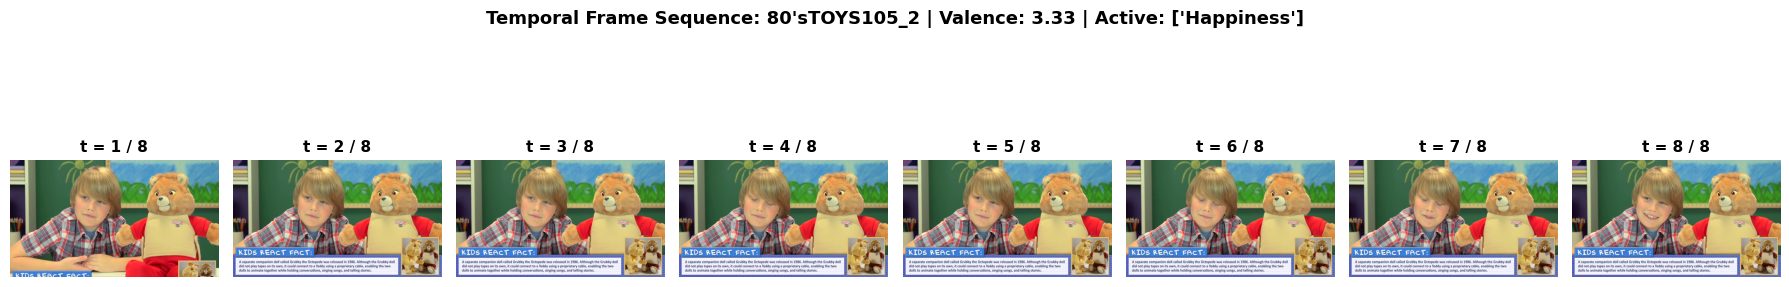

In [3]:
# Select a sample video clip
sample = train_samples[0]
video_path = sample["video_path"]
sample_id = sample["sample_id"]
print(f"Analyzing clip: {sample_id} ({video_path})")

# Extract T = 8 uniform frames
NUM_FRAMES = 8
frames = extract_sample_frames(video_path, num_frames=NUM_FRAMES)
print(f"Extracted frames count : {len(frames)}")
print(f"Individual frame shape : {frames[0].shape} (Height x Width x Channels)")
print(f"Pixel value range      : [{frames[0].min()}, {frames[0].max()}] (uint8)")

# Visualize the sequence along the temporal timeline
fig, axes = plt.subplots(1, NUM_FRAMES, figsize=(18, 3.5))
for t, frame in enumerate(frames):
    axes[t].imshow(frame)
    axes[t].set_title(f"t = {t+1} / {NUM_FRAMES}", fontsize=11, fontweight="bold")
    axes[t].axis("off")

active_emotions = [k for k, v in sample["emotion_labels"].items() if v == 1]
valence_score = sample["other_original_annotations"]["valence"]
plt.suptitle(
    f"Temporal Frame Sequence: {sample_id} | Valence: {valence_score:.2f} | Active: {active_emotions}",
    fontsize=13,
    fontweight="bold",
    y=1.05
)
plt.tight_layout()
plt.show()


---
## Section 4: Frame Preprocessing and ImageNet Normalization

Pretrained convolutional networks (ResNet-18) expect inputs normalized with ImageNet channel statistics:
$$\mu = [0.485, 0.456, 0.406], \quad \sigma = [0.229, 0.224, 0.225]$$
and resized to standard dimensions ($224 \times 224$).

Here we inspect our reusable transformation module: `src/sentiment_derivation/data/transforms.py`.


In [4]:
from sentiment_derivation.data.transforms import (
    IMAGENET_MEAN,
    IMAGENET_STD,
    get_frame_transform,
    VideoClipTransform,
)

print(f"ImageNet Channel Means : {IMAGENET_MEAN}")
print(f"ImageNet Channel Stds  : {IMAGENET_STD}")

# Instantiate the clip transform module
TARGET_SIZE = (224, 224)
clip_transform = VideoClipTransform(image_size=TARGET_SIZE, is_train=False)

# Transform the list of T NumPy frames
# Converts list of (H, W, 3) uint8 arrays -> Tensor of shape (T, 3, 224, 224) float32
transformed_clip = clip_transform(frames)

print(f"Transformed tensor shape: {transformed_clip.shape}")
print(f"Tensor data type        : {transformed_clip.dtype}")
print(f"Tensor min/max values   : [{transformed_clip.min():.3f}, {transformed_clip.max():.3f}]")


ImageNet Channel Means : (0.485, 0.456, 0.406)
ImageNet Channel Stds  : (0.229, 0.224, 0.225)
Transformed tensor shape: torch.Size([8, 3, 224, 224])
Tensor data type        : torch.float32
Tensor min/max values   : [-2.036, 2.640]


In [5]:
from sentiment_derivation.encoders.video_encoder import VideoEncoder
import torch

enc = VideoEncoder().eval()
with torch.no_grad():
    out = enc(transformed_clip.unsqueeze(0))
print(out["features"].shape)   # expect torch.Size([1, 8, 512])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\nilad/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


torch.Size([1, 8, 512])


---
## Section 5: Pretrained ResNet-18 Backbone Architecture Analysis

ResNet-18 is our baseline visual encoder per `AGENTS.md`. 
Let's analyze its layer hierarchy:
- Input: $(N, 3, 224, 224)$
- `conv1` + `bn1` + `relu` + `maxpool` $\to (N, 64, 56, 56)$
- `layer1` (2 BasicBlocks) $\to (N, 64, 56, 56)$
- `layer2` (2 BasicBlocks) $\to (N, 128, 28, 28)$
- `layer3` (2 BasicBlocks) $\to (N, 256, 14, 14)$
- `layer4` (2 BasicBlocks) $\to (N, 512, 7, 7)$
- `avgpool` (Global Average Pooling) $\to (N, 512, 1, 1)$
- Flatten $\to (N, 512)$ **penultimate visual embedding**
- `fc` (Linear 512 $\to$ 1000) **ImageNet classification head — replaced with `nn.Identity()`**


In [6]:
# Conceptual inspection of the ResNet-18 feature extraction pipeline
print("ResNet-18 Feature Extraction Hierarchy:")
layer_specs = [
    ("Input Frame", "(3, 224, 224)", "Raw RGB video frame"),
    ("conv1 + maxpool", "(64, 56, 56)", "Low-level edges and textures"),
    ("layer1 (BasicBlock x2)", "(64, 56, 56)", "Early local facial features"),
    ("layer2 (BasicBlock x2)", "(128, 28, 28)", "Intermediate facial patterns"),
    ("layer3 (BasicBlock x2)", "(256, 14, 14)", "Higher-order expression cues"),
    ("layer4 (BasicBlock x2)", "(512, 7, 7)", "Complex affective & facial representations"),
    ("avgpool (Global Pool)", "(512, 1, 1)", "Spatially aggregated visual embedding"),
    ("fc -> nn.Identity()", "(512,)", "Frame-level visual embedding vector"),
]

display(pd.DataFrame(layer_specs, columns=["Stage", "Output Shape", "Affective Role"]))


ResNet-18 Feature Extraction Hierarchy:


,Stage,Output Shape,Affective Role
0,Input Frame,"(3, 224, 224)",Raw RGB video frame
1,conv1 + maxpool,"(64, 56, 56)",Low-level edges and textures
2,layer1 (BasicBlock x2),"(64, 56, 56)",Early local facial features
3,layer2 (BasicBlock x2),"(128, 28, 28)",Intermediate facial patterns
4,layer3 (BasicBlock x2),"(256, 14, 14)",Higher-order expression cues
5,layer4 (BasicBlock x2),"(512, 7, 7)",Complex affective & facial representations
6,avgpool (Global Pool),"(512, 1, 1)",Spatially aggregated visual embedding
7,fc -> nn.Identity(),"(512,)",Frame-level visual embedding vector


---
## Section 6: Temporal Order Preservation for Downstream BiLSTM

A critical constraint in `AGENTS.md` is:
> **"Temporal analysis must produce transitional embeddings BEFORE final sentiment derivation."**
> **"Do not average or collapse temporal frame features during encoding."**

To satisfy this:
1. A video batch has shape $(B, T, C, H, W)$ where $B$ is batch size and $T$ is sequence length.
2. We **fold** the batch and temporal dimensions: $N = B \times T$, giving $(B \cdot T, C, H, W)$.
3. ResNet-18 processes all $B \cdot T$ frames in parallel: $(B \cdot T, 512)$.
4. We **unfold** back to $(B, T, 512)$, preserving the exact frame order $t_1, t_2, \dots, t_T$!
5. This sequence is then consumed by the Stage 4 BiLSTM temporal encoder.


In [7]:
# Demonstrate folding and unfolding logic
batch_size = 4
num_frames = 16
channels = 3
height, width = 224, 224
feature_dim = 512

print(f"1. Input batched video tensor : ({batch_size}, {num_frames}, {channels}, {height}, {width}) [B, T, C, H, W]")

# Fold
folded_shape = (batch_size * num_frames, channels, height, width)
print(f"2. Folded for 2D CNN backbone : {folded_shape} [B*T, C, H, W]")

# ResNet-18 forward pass output
features_folded_shape = (batch_size * num_frames, feature_dim)
print(f"3. ResNet-18 pooled output    : {features_folded_shape} [B*T, 512]")

# Unfold
unfolded_shape = (batch_size, num_frames, feature_dim)
print(f"4. Unfolded temporal sequence : {unfolded_shape} [B, T, 512] <-- Preserved for BiLSTM!")


1. Input batched video tensor : (4, 16, 3, 224, 224) [B, T, C, H, W]
2. Folded for 2D CNN backbone : (64, 3, 224, 224) [B*T, C, H, W]
3. ResNet-18 pooled output    : (64, 512) [B*T, 512]
4. Unfolded temporal sequence : (4, 16, 512) [B, T, 512] <-- Preserved for BiLSTM!


---
## Section 7: VideoEncoder Module Contract & Verification

Here we review our production module `src/sentiment_derivation/encoders/video_encoder.py` and its configuration in `configs/model.yaml`.


In [8]:
# Inspect configs/model.yaml configuration
import yaml

config_path = PROJECT_ROOT / "configs" / "model.yaml"
with open(config_path, "r", encoding="utf-8") as f:
    model_cfg = yaml.safe_load(f)

print("Video Encoder Configuration (configs/model.yaml):")
print(json.dumps(model_cfg.get("video_encoder", {}), indent=2))

# Module contract specifications
contract = {
    "Module Class": "VideoEncoder",
    "Module Location": "src/sentiment_derivation/encoders/video_encoder.py",
    "Backbone": "ResNet-18 (ImageNet pretrained)",
    "Feature Dimension": 512,
    "Default Mode": "Frozen backbone (requires_grad = False)",
    "Input Tensor": "(B, T, 3, 224, 224) or (T, 3, 224, 224)",
    "Output Tensor": "(B, T, 512) or (T, 512)",
    "Contract Output": "{'features': Tensor, 'metadata': {'modality': 'video', 'num_frames': T, ...}}",
}

display(pd.DataFrame(list(contract.items()), columns=["Property", "Specification"]))


Video Encoder Configuration (configs/model.yaml):
{
  "architecture": "resnet18",
  "pretrained": true,
  "weights": "DEFAULT",
  "feature_dim": 512,
  "freeze_backbone": true,
  "apply_transforms": false,
  "image_size": [
    224,
    224
  ],
  "normalization": {
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ]
  }
}


,Property,Specification
0,Module Class,VideoEncoder
1,Module Location,src/sentiment_derivation/encoders/video_encode...
2,Backbone,ResNet-18 (ImageNet pretrained)
3,Feature Dimension,512
4,Default Mode,Frozen backbone (requires_grad = False)
5,Input Tensor,"(B, T, 3, 224, 224) or (T, 3, 224, 224)"
6,Output Tensor,"(B, T, 512) or (T, 512)"
7,Contract Output,"{'features': Tensor, 'metadata': {'modality': ..."


---
## Section 8: Summary and Downstream Integration

### Key Insights from Video Modality Experiments:
1. **Frame Dynamics**: Children's emotional reactions in EmoReact change rapidly across short 3-10 second intervals. Sampling $T = 16$ uniform frames provides a balanced compromise between temporal resolution and GPU memory efficiency.
2. **Feature Quality**: Pretrained ResNet-18 provides strong generic edge, facial landmark, and expression representations in its 512-dimensional penultimate layer.
3. **Parameter Freezing**: In early experimental phases, keeping ResNet-18 weights frozen prevents overfitting on the 1,102 dataset clips while allowing the Stage 4 BiLSTM temporal encoder to learn transition dynamics.
4. **Complementary Features**: OpenFace features (action units, landmarks, gaze) already in the dataset will later fuse with these ResNet-18 visual embeddings during Stage 3 Multimodal Fusion.
